# EDA dữ liệu hành vi mô phỏng (Tuần 8, Bước 2)

Notebook này khám phá dữ liệu do `python -m app.simulation` sinh ra (tài khoản `@mophong.test`): đơn hàng, lượt xem, giỏ hàng, đánh giá, khảo sát. Mục đích:

1. Kiểm tra dữ liệu có hình dạng giống một shop thật (đơn theo thời gian, sản phẩm bán chạy, phễu xem → giỏ → mua).
2. Xem dữ liệu có đủ tín hiệu cho **gợi ý sản phẩm** (ma trận người dùng–sản phẩm, mua cùng) và **phân nhóm khách hàng** (R, F, M).

Chạy lại (trong `ml-service/`, CSDL đã có dữ liệu mô phỏng, đã nạp `MYSQL_ROOT_PASSWORD`):

```
uv sync --group eda
uv run --group eda jupyter execute --inplace notebooks/eda_du_lieu_mo_phong.ipynb
```

Hoặc mở bằng VS Code, chọn kernel `.venv` của ml-service.

In [1]:
import os
import sys
from itertools import combinations

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

# Notebook chạy trong ml-service/notebooks/: thêm ml-service/ vào đường dẫn để import app.
sys.path.insert(0, os.path.abspath(".."))

from app.config import Settings
from app.db import create_db_engine
from app.simulation.__main__ import DEFAULT_SEED
from app.simulation.personas import DEMO_ACCOUNTS, PERSONAS, assign_personas

engine = create_db_engine(Settings.from_env())
SEED = int(os.environ.get("SIM_SEED", DEFAULT_SEED))  # seed đã dùng khi sinh dữ liệu

# Bảng màu đã kiểm tra cho người mù màu: 1 màu cho độ lớn, 7 màu cố định cho 7 kiểu khách.
BLUE = "#2a78d6"
PERSONA_COLORS = dict(
    zip(
        PERSONAS,
        ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"],
        strict=True,
    )
)
plt.rcParams.update(
    {
        "figure.dpi": 80,
        "figure.figsize": (8, 3.4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e4e3df",
        "axes.edgecolor": "#8a8984",
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
    }
)
vnd = FuncFormatter(lambda x, _: f"{x / 1e6:.1f} tr" if x >= 1e6 else f"{x / 1e3:.0f}k")

## 1. Đọc dữ liệu

In [2]:
SIM = "RIGHT(a.email, 13) = '@mophong.test'"


def sql(query):
    return pd.read_sql(query, engine)


accounts = sql(
    f"SELECT a.id, a.email, a.gender, a.birthdate, a.created_at FROM account a WHERE {SIM}"
)
orders = sql(
    f"SELECT o.id, o.account_id, o.status, o.payment_method, o.subtotal_amount, o.shipping_fee, "
    f"o.total_amount, o.created_at FROM orders o JOIN account a ON a.id = o.account_id WHERE {SIM}"
)
items = sql(
    f"SELECT i.order_id, o.account_id, o.status, v.product_id, p.category_id, c.name AS category, "
    f"p.brand_id, i.quantity, i.line_total FROM order_item i JOIN orders o ON o.id = i.order_id "
    f"JOIN account a ON a.id = o.account_id JOIN product_variant v ON v.id = i.variant_id "
    f"JOIN product p ON p.id = v.product_id JOIN category c ON c.id = p.category_id WHERE {SIM}"
)
views = sql(
    f"SELECT v.account_id, v.product_id, v.viewed_at FROM product_view_log v "
    f"JOIN account a ON a.id = v.account_id WHERE {SIM}"
)
carts = sql(
    f"SELECT e.account_id, e.product_id FROM product_event_log e "
    f"JOIN account a ON a.id = e.account_id WHERE {SIM} AND e.event_type = 'ADD_TO_CART'"
)
reviews = sql(
    f"SELECT r.account_id, r.product_id, r.rating FROM review r "
    f"JOIN account a ON a.id = r.account_id WHERE {SIM}"
)
surveys = sql(
    f"SELECT s.account_id, s.status, s.style FROM survey_result s "
    f"JOIN account a ON a.id = s.account_id WHERE {SIM}"
)
products = sql("SELECT COUNT(*) AS n FROM product WHERE deleted_at IS NULL")["n"][0]

# Nhãn kiểu khách thật (persona) dựng lại từ seed, để so với kết quả phân nhóm ở Tuần 9.
regular = accounts["email"].str.match(r"kh\d{4}@")
labels = dict(
    zip(
        sorted(accounts.loc[regular, "email"]),
        assign_personas(int(regular.sum()), SEED),
        strict=True,
    )
)
labels |= {d.email: d.persona for d in DEMO_ACCOUNTS}
accounts["persona"] = accounts["email"].map(labels)
persona_of = accounts.set_index("id")["persona"]

pd.DataFrame(
    {
        "Số dòng": [
            len(accounts),
            len(orders),
            len(items),
            len(views),
            len(carts),
            len(reviews),
            len(surveys),
            products,
        ]
    },
    index=[
        "Khách mô phỏng",
        "Đơn hàng",
        "Dòng đơn",
        "Lượt xem",
        "Thêm vào giỏ",
        "Đánh giá",
        "Kết quả khảo sát",
        "Sản phẩm đang bán",
    ],
)

,Số dòng
Khách mô phỏng,306
Đơn hàng,1478
Dòng đơn,2892
Lượt xem,31031
Thêm vào giỏ,3902
Đánh giá,896
Kết quả khảo sát,237
Sản phẩm đang bán,1050


## 2. Khách hàng theo kiểu (persona)

Bộ sinh chia khách thành 7 kiểu khác nhau rõ về R (mua gần đây), F (số đơn), M (tổng tiền). Đây là "đáp án" để kiểm tra K-Means ở Tuần 9 có tìm lại được các nhóm này không.

In [3]:
summary = pd.DataFrame(
    {
        "Mô tả": {code: p.label for code, p in PERSONAS.items()},
        "Số khách": accounts["persona"].value_counts(),
    }
).loc[list(PERSONAS)]
summary

,Mô tả,Số khách
VIP,"Khách VIP: mua nhiều, thường xuyên, chi nhiều",22
LOYAL,Khách quen: mua đều đặn,69
SAVER,"Khách tiết kiệm: mua khá thường xuyên, món rẻ",61
NEW,"Khách mới: vừa đăng ký, 1-2 đơn",47
AT_RISK,"Khách sắp rời bỏ: từng mua khá nhiều, 4-10 thá...",30
CHURNED,"Khách đã rời bỏ: mua ít, lần cuối 8-12 tháng t...",37
BROWSER,Chỉ xem: chưa mua đơn nào,40


## 3. Đơn hàng theo thời gian

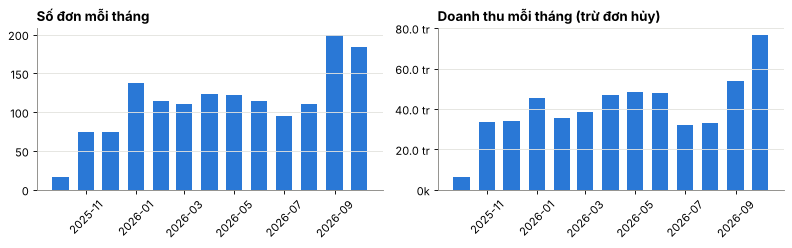

In [4]:
orders["month"] = orders["created_at"].dt.to_period("M").dt.to_timestamp()
monthly = orders.groupby("month").agg(
    don=("id", "size"),
    doanh_thu=("total_amount", lambda s: s[orders.loc[s.index, "status"] != "CANCELLED"].sum()),
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(monthly.index, monthly["don"], width=20, color=BLUE)
axes[0].set_title("Số đơn mỗi tháng")
axes[1].bar(monthly.index, monthly["doanh_thu"], width=20, color=BLUE)
axes[1].set_title("Doanh thu mỗi tháng (trừ đơn hủy)")
axes[1].yaxis.set_major_formatter(vnd)
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

Tháng đầu ít đơn vì khách mới bắt đầu đăng ký. Hai tháng gần nhất nhiều đơn hơn vì có thêm khách mới (đăng ký trong 40 ngày) và mỗi khách còn hoạt động (VIP, quen, tiết kiệm) đều có 1 đơn gần đây. Các tháng giữa ổn định: bộ sinh không mô phỏng mùa sale.

In [5]:
pd.crosstab(orders["status"], orders["payment_method"], margins=True, margins_name="Tổng")

payment_method,COD,ONLINE,Tổng
status,,,
CANCELLED,174,0,174
DELIVERED,913,363,1276
PENDING,1,1,2
PROCESSING,10,2,12
SHIPPING,11,3,14
Tổng,1109,369,1478


count       1304.0
mean      385391.0
std       551884.0
min         1900.0
25%        72750.0
50%       195650.0
75%       463250.0
max      5440926.0
Name: subtotal_amount, dtype: float64
Tỉ lệ đơn được miễn phí ship: 23%


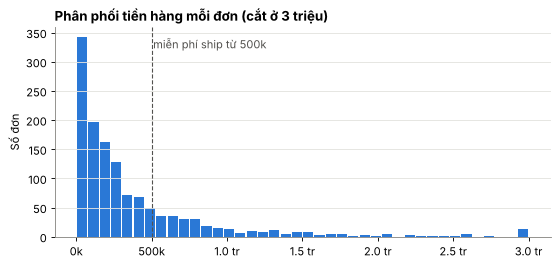

In [6]:
fig, ax = plt.subplots()
paid = orders[orders["status"] != "CANCELLED"]
ax.hist(paid["subtotal_amount"].clip(upper=3_000_000), bins=40, color=BLUE, rwidth=0.9)
ax.axvline(500_000, color="#52514e", linestyle="--", linewidth=1)
ax.text(510_000, ax.get_ylim()[1] * 0.9, "miễn phí ship từ 500k", color="#52514e")
ax.xaxis.set_major_formatter(vnd)
ax.set_title("Phân phối tiền hàng mỗi đơn (cắt ở 3 triệu)")
ax.set_ylabel("Số đơn")
print(paid["subtotal_amount"].describe().round(0))
print(f"Tỉ lệ đơn được miễn phí ship: {(paid['shipping_fee'] == 0).mean():.0%}")

## 4. Sản phẩm và danh mục

707/1050 sản phẩm có người mua (67%).
20% sản phẩm bán chạy nhất chiếm 55% số lượng bán.


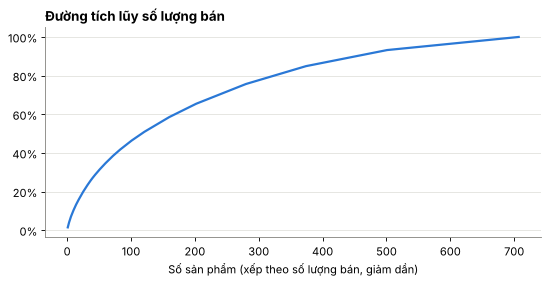

In [7]:
sold = items[items["status"] != "CANCELLED"].groupby("product_id")["quantity"].sum()
sold = sold.sort_values(ascending=False)
share = sold.cumsum() / sold.sum()
top20 = share.iloc[max(int(len(sold) * 0.2) - 1, 0)]
fig, ax = plt.subplots()
ax.plot(range(1, len(share) + 1), share.values, color=BLUE, linewidth=2)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Số sản phẩm (xếp theo số lượng bán, giảm dần)")
ax.set_title("Đường tích lũy số lượng bán")
print(f"{len(sold)}/{products} sản phẩm có người mua ({len(sold) / products:.0%}).")
print(f"20% sản phẩm bán chạy nhất chiếm {top20:.0%} số lượng bán.")

Phân phối "đuôi dài": một nhóm nhỏ sản phẩm bán rất chạy, phần lớn bán ít hoặc chưa bán. Gợi ý theo bán chạy vì thế làm phương án dự phòng tốt cho khách mới, nhưng nếu chỉ dùng nó thì phần lớn danh mục không bao giờ được giới thiệu: lý do cần gợi ý theo nội dung và hành vi.

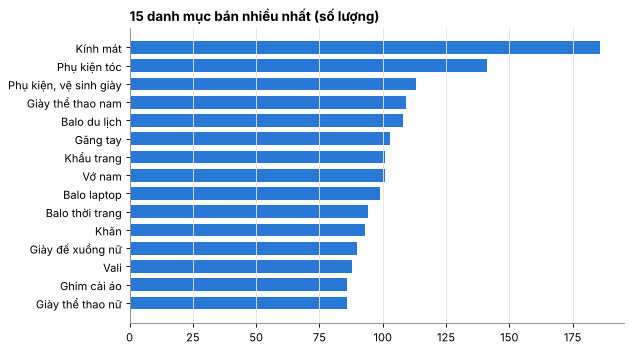

In [8]:
by_category = (
    items[items["status"] != "CANCELLED"].groupby("category")["quantity"].sum().nlargest(15)
)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(by_category.index[::-1], by_category.values[::-1], color=BLUE, height=0.7)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("15 danh mục bán nhiều nhất (số lượng)")
fig.tight_layout()

## 5. Phễu xem → thêm vào giỏ → mua

In [9]:
funnel = pd.DataFrame(
    {
        "Khách": [
            views["account_id"].nunique(),
            carts["account_id"].nunique(),
            orders["account_id"].nunique(),
        ],
        "Lượt": [len(views), len(carts), len(items)],
    },
    index=["Xem sản phẩm", "Thêm vào giỏ", "Đặt mua"],
)
funnel["Tỉ lệ lượt so với xem"] = (funnel["Lượt"] / len(views)).map("{:.1%}".format)
funnel

,Khách,Lượt,Tỉ lệ lượt so với xem
Xem sản phẩm,304,31031,100.0%
Thêm vào giỏ,301,3902,12.6%
Đặt mua,264,2892,9.3%


## 6. R, F, M cho phân nhóm khách hàng

258 khách có đơn đã giao.


,R,F,M
count,258.0,258.0,258.0
mean,77.0,5.0,2027146.0
std,96.0,3.0,3038024.0
min,4.0,1.0,34400.0
25%,14.0,2.0,480838.0
50%,29.0,5.0,1005650.0
75%,129.0,7.0,2156409.0
max,349.0,16.0,19084204.0


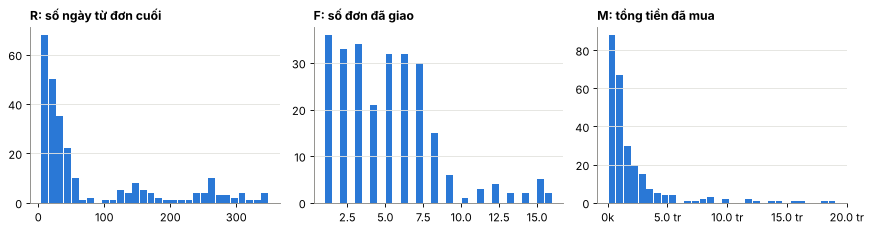

In [10]:
now = max(orders["created_at"].max(), views["viewed_at"].max())
delivered = orders[orders["status"] == "DELIVERED"]
rfm = delivered.groupby("account_id").agg(
    last=("created_at", "max"), F=("id", "size"), M=("total_amount", "sum")
)
rfm["R"] = (now - rfm["last"]).dt.days
rfm["persona"] = persona_of.reindex(rfm.index).values

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, col, title in zip(
    axes,
    ["R", "F", "M"],
    ["R: số ngày từ đơn cuối", "F: số đơn đã giao", "M: tổng tiền đã mua"],
    strict=True,
):
    ax.hist(rfm[col], bins=30, color=BLUE, rwidth=0.9)
    ax.set_title(title, fontsize=11)
axes[2].xaxis.set_major_formatter(vnd)
fig.tight_layout()
print(f"{len(rfm)} khách có đơn đã giao.")
rfm[["R", "F", "M"]].describe().round(0)

F và M lệch phải mạnh (vài khách VIP mua rất nhiều): trước khi chạy K-Means ở Tuần 9 nên lấy log rồi chuẩn hóa (StandardScaler), nếu không M sẽ quyết định gần như toàn bộ khoảng cách.

,R,F,M
persona,,,
AT_RISK,154.0,3.0,1038762.0
CHURNED,268.0,2.0,426450.0
LOYAL,22.0,7.0,2085950.0
NEW,19.0,1.0,253500.0
SAVER,28.0,5.0,878500.0
VIP,8.0,12.0,9221650.0


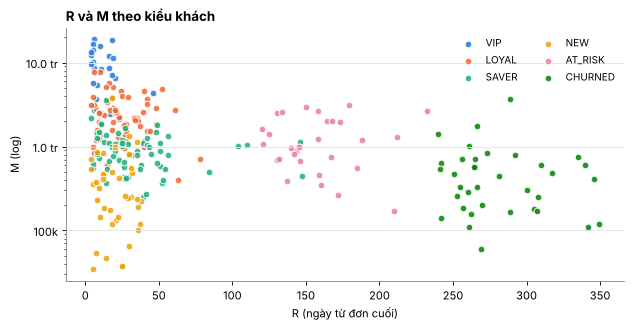

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for code, color in PERSONA_COLORS.items():
    part = rfm[rfm["persona"] == code]
    if len(part):
        ax.scatter(
            part["R"],
            part["M"],
            s=36,
            color=color,
            label=code,
            alpha=0.85,
            edgecolors="white",
            linewidths=1,
        )
ax.set_yscale("log")
ax.yaxis.set_major_formatter(vnd)
ax.set_xlabel("R (ngày từ đơn cuối)")
ax.set_ylabel("M (log)")
ax.set_title("R và M theo kiểu khách")
ax.legend(frameon=False, ncol=2, fontsize=9)
fig.tight_layout()
rfm.groupby("persona")[["R", "F", "M"]].median().loc[lambda d: d.index.isin(PERSONAS)].round(0)

Các kiểu khách tách khá rõ theo R (khách rời bỏ và sắp rời bỏ ở bên phải) và M (VIP ở trên cùng); khách quen và khách tiết kiệm chồng lên nhau một phần, khác nhau chủ yếu ở M. K-Means trên (log R, log F, log M) có cơ sở để tìm ra 4–6 nhóm.

## 7. Ma trận người dùng – sản phẩm

In [12]:
buyers = items.groupby("account_id")["product_id"].nunique()
viewers = views.groupby("account_id")["product_id"].nunique()
n_users = len(accounts)
density = pd.DataFrame(
    {
        "Khách có tương tác": [buyers.size, viewers.size],
        "Sản phẩm khác nhau / khách (trung vị)": [buyers.median(), viewers.median()],
        "Độ phủ ma trận": [
            f"{items.drop_duplicates(['account_id', 'product_id']).shape[0] / (n_users * products):.2%}",
            f"{views.drop_duplicates(['account_id', 'product_id']).shape[0] / (n_users * products):.2%}",
        ],
    },
    index=["Đã mua", "Đã xem"],
)
density

,Khách có tương tác,Sản phẩm khác nhau / khách (trung vị),Độ phủ ma trận
Đã mua,264,8.5,0.77%
Đã xem,304,42.0,4.08%


Ma trận mua rất thưa (dưới 1% ô có giá trị), ma trận xem dày hơn nhiều lần. Gợi ý theo hành vi nên dùng cả lượt xem và thêm vào giỏ (có trọng số nhỏ hơn mua), còn phần gợi ý theo nội dung (danh mục, thương hiệu, giá, tên sản phẩm) giúp khi khách có ít tương tác.

## 8. Hay mua cùng

In [13]:
pairs = {}
for _, group in items.groupby("order_id"):
    for a, b in combinations(sorted(set(group["category"])), 2):
        pairs[(a, b)] = pairs.get((a, b), 0) + 1
multi = items.groupby("order_id")["product_id"].nunique()
print(f"{(multi > 1).mean():.0%} số đơn có từ 2 sản phẩm.")
pd.Series(pairs, name="Số đơn").nlargest(10).rename_axis(["Danh mục 1", "Danh mục 2"]).to_frame()

63% số đơn có từ 2 sản phẩm.


Số đơn
Danh mục 1        Danh mục 2              
Balo laptop       Balo thời trang       11
Balo thời trang   Ví nam                 9
Balo laptop       Ví nam                 9
Balo thời trang   Khẩu trang             8
Giày thể thao nam Khẩu trang             8
                  Vớ nam                 8
Kính mát          Vali                   8
                  Phụ kiện tóc           7
                  Nón nữ                 7
Balo du lịch      Phụ kiện du lịch       7

Các cặp danh mục bổ trợ (balo + ví, giày thể thao + vớ, kính mát + vali...) xuất hiện nhiều, đúng như bộ sinh mô phỏng mua theo dịp sử dụng. Đây là dữ liệu cho phần "hay mua cùng" của gợi ý hybrid.

## 9. Đánh giá và khảo sát

Điểm trung bình 4.14; 459 sản phẩm có đánh giá.


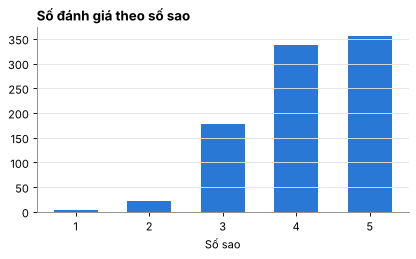

In [14]:
fig, ax = plt.subplots(figsize=(6, 3))
counts = reviews["rating"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.6)
ax.set_title("Số đánh giá theo số sao")
ax.set_xlabel("Số sao")
print(
    f"Điểm trung bình {reviews['rating'].mean():.2f}; {reviews['product_id'].nunique()} sản phẩm có đánh giá."
)

In [15]:
surveys["persona"] = persona_of.reindex(surveys["account_id"]).values
completed = surveys[surveys["status"] == "COMPLETED"]
print(surveys["status"].value_counts().to_string())
pd.crosstab(completed["persona"], completed["style"]).reindex(
    [p for p in PERSONAS if p in set(completed["persona"])]
)

status
COMPLETED    200
SKIPPED       37


style,BRAND,QUALITY,SAVER,TREND
persona,,,,
VIP,7,5,0,2
LOYAL,5,21,12,9
SAVER,0,0,25,13
NEW,0,8,10,12
AT_RISK,2,9,5,4
CHURNED,0,6,13,8
BROWSER,2,6,7,9


## 10. Kết luận cho các bước sau

- Dữ liệu có đủ cấu trúc: đuôi dài bán chạy, phễu xem → giỏ → mua, cặp danh mục mua cùng, R/F/M khác nhau rõ giữa các kiểu khách.
- **Gợi ý (Bước 3):** kết hợp theo nội dung (danh mục, thương hiệu, giá, tên) + hay mua cùng + khảo sát + bán chạy; dùng cả lượt xem và thêm giỏ vì ma trận mua quá thưa.
- **Phân nhóm (Tuần 9):** lấy log F, M trước khi chuẩn hóa; so nhóm K-Means với kiểu khách thật bằng chỉ số Adjusted Rand.
- Dữ liệu là mô phỏng: các con số chỉ dùng để kiểm tra thuật toán và demo, không phản ánh hành vi khách thật.